                 PHANTOM
       Missing Event Intelligence Engine

Original events : 80
Observed events : 76
Hidden events   : 4


                 PHANTOM INVESTIGATION REPORT

Observed events        : 76
Suspicious gaps        : 5
High-risk anomalies    : 0
Medium-risk anomalies  : 5
Average event gap      : 8.16 min
Largest event gap      : 23.03 min
Timeline integrity     : 97.33/100

TOP PHANTOM EVENTS
----------------------------------------------------------------------


,investigation_id,previous_event,current_event,suspected_missing_event,gap_minutes,confidence,severity
0,1,DATA_UPLOAD,PROCESSING,VALIDATION,15.82,52.5,MEDIUM
1,2,REPORT_GENERATED,LOGIN,LOGOUT,8.01,52.3,MEDIUM
2,3,LOGOUT,LOGIN,UNKNOWN,1.11,52.3,MEDIUM
3,4,VALIDATION,MODEL_INFERENCE,PROCESSING,23.03,52.0,MEDIUM
4,5,LOGOUT,DATA_UPLOAD,UNKNOWN,7.18,52.0,MEDIUM



GROUND TRUTH VALIDATION
----------------------------------------------------------------------
Actual hidden event types : ['LOGIN', 'LOGOUT', 'PROCESSING', 'VALIDATION']
Detected event types      : ['LOGOUT', 'PROCESSING', 'UNKNOWN', 'VALIDATION']
Detected overlap          : ['LOGOUT', 'PROCESSING', 'VALIDATION']
Event-type recovery       : 75.00%


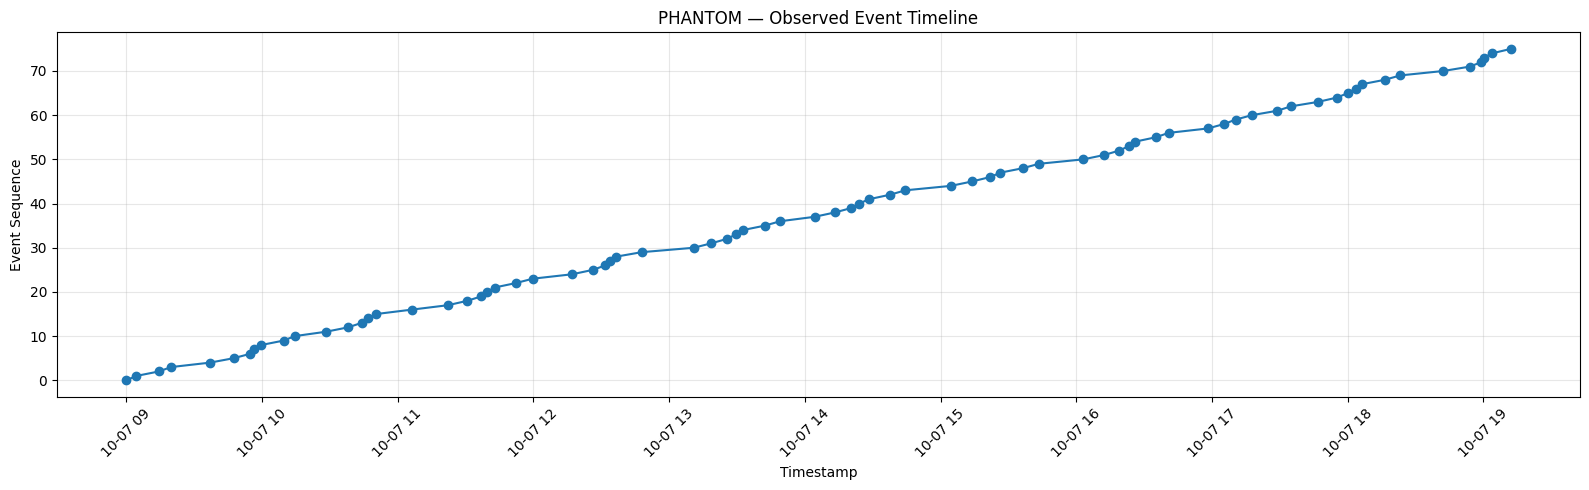

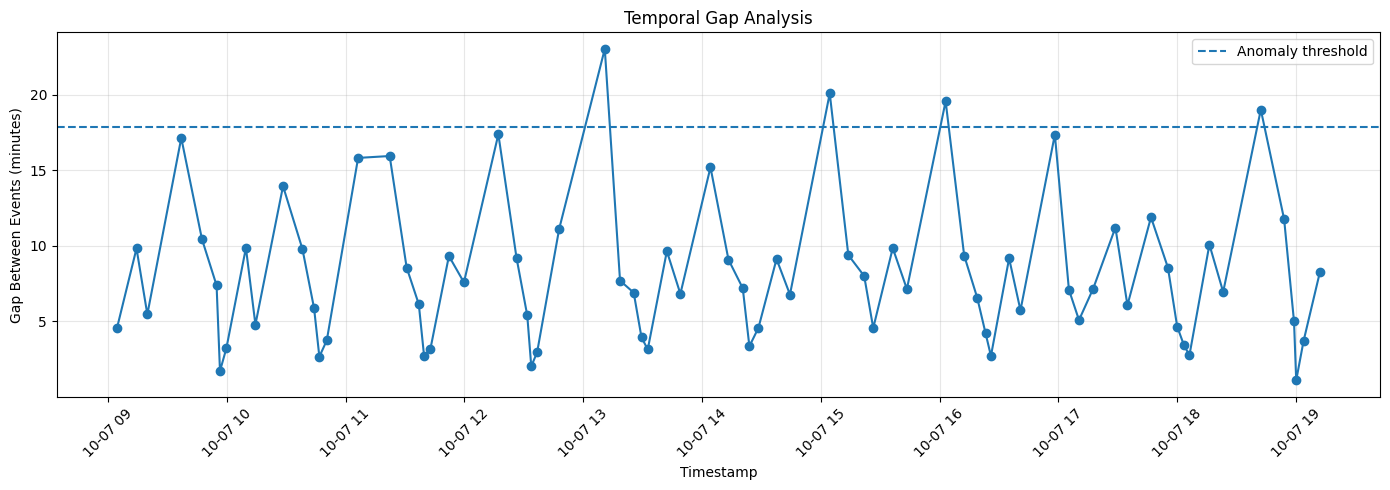

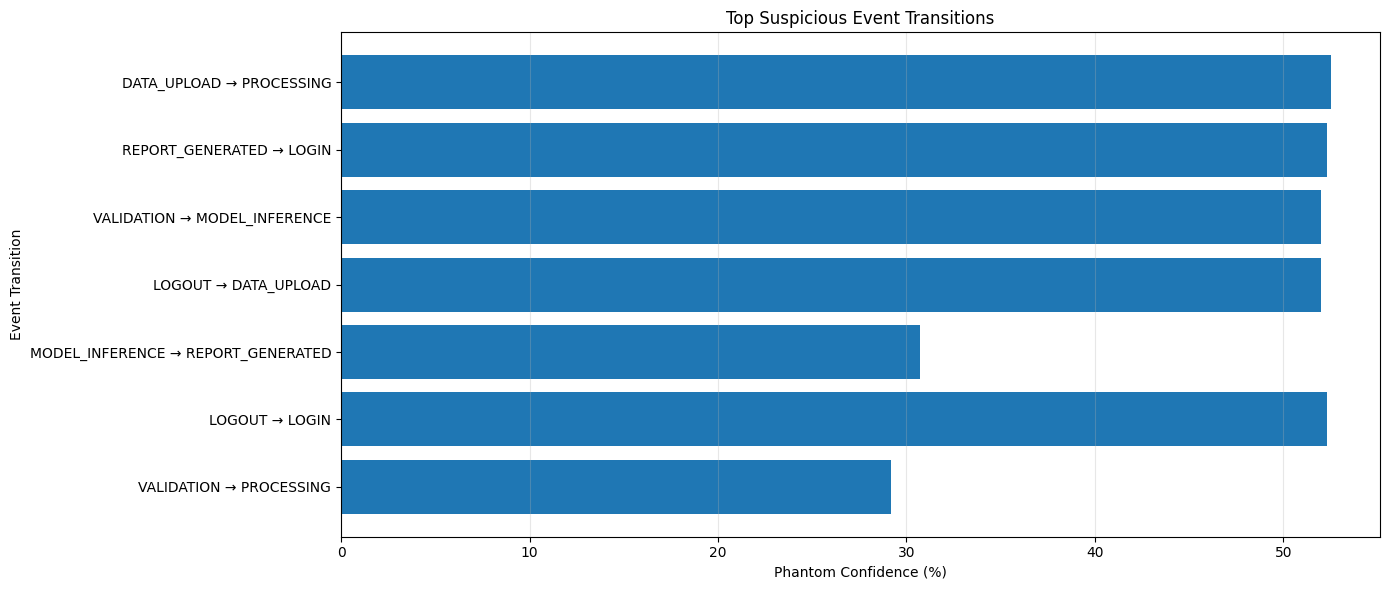

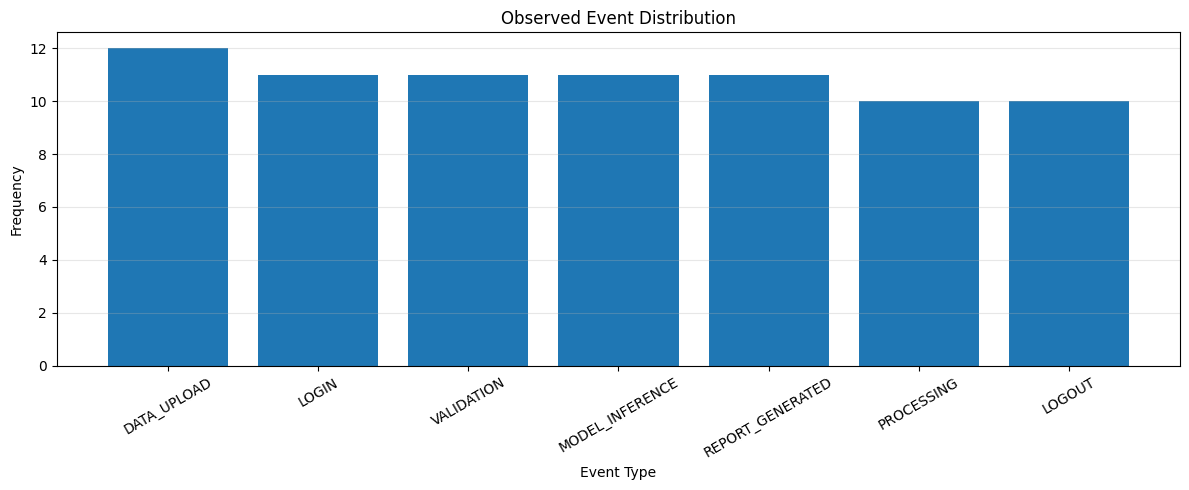



                 AI INVESTIGATION SUMMARY


KeyError: 'evidence'

In [2]:
# ============================================================
# PHANTOM
# Missing Event Intelligence Engine
# ============================================================
# Concept:
# Most systems analyze events that EXIST.
# PHANTOM investigates events that MAY BE MISSING.
#
# Pipeline:
# Event Stream
#      ↓
# Timeline Reconstruction
#      ↓
# Temporal Gap Detection
#      ↓
# Behavioral Pattern Analysis
#      ↓
# Anomaly Scoring
#      ↓
# Missing Event Hypothesis
#      ↓
# Evidence + Confidence
#      ↓
# Investigation Dashboard
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from collections import Counter
import warnings

warnings.filterwarnings("ignore")

np.random.seed(42)

print("=" * 70)
print("                 PHANTOM")
print("       Missing Event Intelligence Engine")
print("=" * 70)


# ============================================================
# 1. GENERATE A REALISTIC EVENT STREAM
# ============================================================

event_types = [
    "LOGIN",
    "DATA_UPLOAD",
    "VALIDATION",
    "PROCESSING",
    "MODEL_INFERENCE",
    "REPORT_GENERATED",
    "LOGOUT"
]

typical_duration = {
    "LOGIN": 2,
    "DATA_UPLOAD": 8,
    "VALIDATION": 5,
    "PROCESSING": 15,
    "MODEL_INFERENCE": 8,
    "REPORT_GENERATED": 4,
    "LOGOUT": 1
}

typical_next_event = {
    "LOGIN": ["DATA_UPLOAD"],
    "DATA_UPLOAD": ["VALIDATION"],
    "VALIDATION": ["PROCESSING"],
    "PROCESSING": ["MODEL_INFERENCE"],
    "MODEL_INFERENCE": ["REPORT_GENERATED"],
    "REPORT_GENERATED": ["LOGOUT"]
}

start_time = datetime(2026, 10, 7, 9, 0, 0)

events = []
current_time = start_time

for i in range(80):

    event = event_types[i % len(event_types)]

    duration = typical_duration[event]

    noise = np.random.normal(0, max(0.5, duration * 0.15))
    duration_actual = max(0.5, duration + noise)

    events.append({
        "event_id": i + 1,
        "timestamp": current_time,
        "event": event,
        "duration_min": round(duration_actual, 2),
        "source": "system_log"
    })

    current_time += timedelta(
        minutes=float(duration_actual + np.random.uniform(0.5, 3))
    )


df = pd.DataFrame(events)


# ============================================================
# 2. CREATE HIDDEN EVENTS
# ============================================================

# We deliberately remove some events.
# PHANTOM must attempt to discover them.

hidden_indices = [16, 31, 48, 63]

hidden_events = df.loc[hidden_indices].copy()

observed_df = df.drop(hidden_indices).reset_index(drop=True)

print("\nOriginal events :", len(df))
print("Observed events :", len(observed_df))
print("Hidden events   :", len(hidden_events))


# ============================================================
# 3. TEMPORAL FEATURE ENGINEERING
# ============================================================

observed_df["timestamp"] = pd.to_datetime(observed_df["timestamp"])

observed_df["previous_timestamp"] = observed_df["timestamp"].shift(1)

observed_df["gap_minutes"] = (
    observed_df["timestamp"] -
    observed_df["previous_timestamp"]
).dt.total_seconds() / 60

observed_df["next_event"] = observed_df["event"].shift(-1)

observed_df["previous_event"] = observed_df["event"].shift(1)


# ============================================================
# 4. LEARN NORMAL EVENT TRANSITIONS
# ============================================================

transition_counts = {}

for _, row in observed_df.dropna(subset=["previous_event"]).iterrows():

    prev_event = row["previous_event"]
    current_event = row["event"]

    if prev_event not in transition_counts:
        transition_counts[prev_event] = Counter()

    transition_counts[prev_event][current_event] += 1


def transition_probability(previous_event, current_event):

    if previous_event not in transition_counts:
        return 0

    counts = transition_counts[previous_event]

    total = sum(counts.values())

    if total == 0:
        return 0

    return counts[current_event] / total


# ============================================================
# 5. NORMAL GAP STATISTICS
# ============================================================

gap_statistics = (
    observed_df
    .groupby(["previous_event", "event"])["gap_minutes"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

gap_statistics["std"] = gap_statistics["std"].fillna(1)


def expected_gap(previous_event, current_event):

    row = gap_statistics[
        (gap_statistics["previous_event"] == previous_event) &
        (gap_statistics["event"] == current_event)
    ]

    if len(row) == 0:
        return None, None

    return float(row.iloc[0]["mean"]), float(row.iloc[0]["std"])


# ============================================================
# 6. PHANTOM DETECTION ENGINE
# ============================================================

candidates = []

for i in range(1, len(observed_df)):

    previous_row = observed_df.iloc[i - 1]
    current_row = observed_df.iloc[i]

    previous_event = previous_row["event"]
    current_event = current_row["event"]

    gap = current_row["gap_minutes"]

    # --------------------------------------------------------
    # GAP SCORE
    # --------------------------------------------------------

    mean_gap, std_gap = expected_gap(
        previous_event,
        current_event
    )

    if mean_gap is not None and std_gap > 0:

        gap_z = abs(gap - mean_gap) / std_gap

    else:

        gap_z = 0


    gap_score = min(gap_z / 3, 1)


    # --------------------------------------------------------
    # TRANSITION SCORE
    # --------------------------------------------------------

    transition_prob = transition_probability(
        previous_event,
        current_event
    )

    transition_score = 1 - transition_prob


    # --------------------------------------------------------
    # SEQUENCE SCORE
    # --------------------------------------------------------

    expected_events = typical_next_event.get(
        previous_event,
        []
    )

    if current_event in expected_events:

        sequence_score = 0

    else:

        sequence_score = 1


    # --------------------------------------------------------
    # COMBINED PHANTOM SCORE
    # --------------------------------------------------------

    phantom_score = (
        0.45 * gap_score +
        0.30 * transition_score +
        0.25 * sequence_score
    )

    candidates.append({
        "previous_event": previous_event,
        "current_event": current_event,
        "timestamp": current_row["timestamp"],
        "gap_minutes": round(gap, 2),
        "gap_score": round(gap_score, 3),
        "transition_score": round(transition_score, 3),
        "sequence_score": round(sequence_score, 3),
        "phantom_score": round(phantom_score, 3)
    })


candidate_df = pd.DataFrame(candidates)


# ============================================================
# 7. INFER WHAT EVENT MAY BE MISSING
# ============================================================

def infer_missing_event(previous_event, current_event):

    expected = typical_next_event.get(
        previous_event,
        []
    )

    if expected and current_event not in expected:

        return expected[0]

    # Detect long gaps and inspect possible intermediate stages

    pipeline = [
        "LOGIN",
        "DATA_UPLOAD",
        "VALIDATION",
        "PROCESSING",
        "MODEL_INFERENCE",
        "REPORT_GENERATED",
        "LOGOUT"
    ]

    if previous_event in pipeline and current_event in pipeline:

        p = pipeline.index(previous_event)
        c = pipeline.index(current_event)

        if c - p > 1:

            return pipeline[p + 1]

    return "UNKNOWN"


candidate_df["suspected_missing_event"] = candidate_df.apply(
    lambda x: infer_missing_event(
        x["previous_event"],
        x["current_event"]
    ),
    axis=1
)


# ============================================================
# 8. CONFIDENCE CALCULATION
# ============================================================

candidate_df["confidence"] = (
    candidate_df["phantom_score"] * 100
).round(2)


candidate_df["severity"] = pd.cut(
    candidate_df["confidence"],
    bins=[-1, 30, 55, 75, 100],
    labels=[
        "LOW",
        "MEDIUM",
        "HIGH",
        "CRITICAL"
    ]
)


# ============================================================
# 9. RANK INVESTIGATIONS
# ============================================================

investigations = (
    candidate_df
    .sort_values(
        "confidence",
        ascending=False
    )
    .reset_index(drop=True)
)

investigations["investigation_id"] = (
    np.arange(len(investigations)) + 1
)


# ============================================================
# 10. DETECT IMPORTANT PHANTOMS
# ============================================================

phantoms = investigations[
    investigations["confidence"] >= 50
].copy()


# ============================================================
# 11. GENERATE EXPLANATIONS
# ============================================================

def generate_explanation(row):

    reasons = []

    if row["gap_score"] > 0.5:
        reasons.append(
            "unusually large temporal gap"
        )

    if row["transition_score"] > 0.5:
        reasons.append(
            "unusual event transition"
        )

    if row["sequence_score"] > 0:
        reasons.append(
            "unexpected workflow sequence"
        )

    if not reasons:
        reasons.append(
            "weak temporal inconsistency"
        )

    return "; ".join(reasons)


investigations["evidence"] = investigations.apply(
    generate_explanation,
    axis=1
)


# ============================================================
# 12. CREATE FINAL PHANTOM REPORT
# ============================================================

report_columns = [
    "investigation_id",
    "previous_event",
    "current_event",
    "suspected_missing_event",
    "gap_minutes",
    "confidence",
    "severity",
    "evidence"
]

report = investigations[report_columns].copy()


# ============================================================
# 13. SYSTEM STATISTICS
# ============================================================

total_events = len(observed_df)

high_risk = len(
    report[report["confidence"] >= 75]
)

medium_risk = len(
    report[
        (report["confidence"] >= 50) &
        (report["confidence"] < 75)
    ]
)

average_gap = observed_df["gap_minutes"].mean()

max_gap = observed_df["gap_minutes"].max()

integrity_score = max(
    0,
    round(
        100 -
        (
            len(phantoms) /
            max(1, len(report))
        ) * 40,
        2
    )
)


# ============================================================
# 14. CONSOLE REPORT
# ============================================================

print("\n")
print("=" * 70)
print("                 PHANTOM INVESTIGATION REPORT")
print("=" * 70)

print(f"\nObserved events        : {total_events}")
print(f"Suspicious gaps        : {len(phantoms)}")
print(f"High-risk anomalies    : {high_risk}")
print(f"Medium-risk anomalies  : {medium_risk}")
print(f"Average event gap      : {average_gap:.2f} min")
print(f"Largest event gap      : {max_gap:.2f} min")
print(f"Timeline integrity     : {integrity_score}/100")


print("\nTOP PHANTOM EVENTS")
print("-" * 70)

if len(phantoms) > 0:

    display(
        phantoms[
            [
                "investigation_id",
                "previous_event",
                "current_event",
                "suspected_missing_event",
                "gap_minutes",
                "confidence",
                "severity"
            ]
        ].head(10)
    )

else:

    print("No strong missing-event candidates detected.")


# ============================================================
# 15. COMPARE WITH HIDDEN GROUND TRUTH
# ============================================================

detected_events = set(
    phantoms["suspected_missing_event"]
)

actual_hidden_events = set(
    hidden_events["event"]
)

intersection = (
    detected_events &
    actual_hidden_events
)

if len(actual_hidden_events) > 0:

    recall = (
        len(intersection) /
        len(actual_hidden_events)
    ) * 100

else:

    recall = 0


print("\nGROUND TRUTH VALIDATION")
print("-" * 70)

print(
    "Actual hidden event types :",
    sorted(actual_hidden_events)
)

print(
    "Detected event types      :",
    sorted(detected_events)
)

print(
    "Detected overlap          :",
    sorted(intersection)
)

print(
    f"Event-type recovery       : {recall:.2f}%"
)


# ============================================================
# 16. VISUALIZATION 1 — EVENT TIMELINE
# ============================================================

plt.figure(figsize=(16, 5))

plt.plot(
    observed_df["timestamp"],
    np.arange(len(observed_df)),
    marker="o"
)

plt.title(
    "PHANTOM — Observed Event Timeline"
)

plt.xlabel("Timestamp")

plt.ylabel("Event Sequence")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 17. VISUALIZATION 2 — GAP ANALYSIS
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    observed_df["timestamp"],
    observed_df["gap_minutes"],
    marker="o"
)

threshold = (
    observed_df["gap_minutes"].mean() +
    2 * observed_df["gap_minutes"].std()
)

plt.axhline(
    threshold,
    linestyle="--",
    label="Anomaly threshold"
)

plt.title(
    "Temporal Gap Analysis"
)

plt.xlabel("Timestamp")

plt.ylabel("Gap Between Events (minutes)")

plt.xticks(rotation=45)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 18. VISUALIZATION 3 — PHANTOM CONFIDENCE
# ============================================================

top = investigations.head(15).copy()

plt.figure(figsize=(14, 6))

labels = (
    top["previous_event"] +
    " → " +
    top["current_event"]
)

plt.barh(
    labels[::-1],
    top["confidence"][::-1]
)

plt.xlabel("Phantom Confidence (%)")

plt.ylabel("Event Transition")

plt.title(
    "Top Suspicious Event Transitions"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 19. VISUALIZATION 4 — EVENT DISTRIBUTION
# ============================================================

event_counts = observed_df["event"].value_counts()

plt.figure(figsize=(12, 5))

plt.bar(
    event_counts.index,
    event_counts.values
)

plt.title(
    "Observed Event Distribution"
)

plt.xlabel("Event Type")

plt.ylabel("Frequency")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 20. FINAL AI-STYLE INVESTIGATION SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("                 AI INVESTIGATION SUMMARY")
print("=" * 70)

if len(phantoms) > 0:

    top_case = phantoms.iloc[0]

    print(
        f"""
Primary anomaly detected:

Between:
    {top_case['previous_event']}

and:
    {top_case['current_event']}

PHANTOM suspects:

    {top_case['suspected_missing_event']}

Confidence:
    {top_case['confidence']}%

Evidence:
    {top_case['evidence']}

Temporal gap:
    {top_case['gap_minutes']} minutes

Severity:
    {top_case['severity']}
"""
    )

else:

    print(
        """
No major phantom events were identified.

The observed timeline appears
structurally consistent.
"""
    )


# ============================================================
# 21. EXPORT RESULTS
# ============================================================

observed_df.to_csv(
    "phantom_observed_events.csv",
    index=False
)

report.to_csv(
    "phantom_investigation_report.csv",
    index=False
)

hidden_events.to_csv(
    "phantom_ground_truth.csv",
    index=False
)

print("\nFiles generated:")
print("1. phantom_observed_events.csv")
print("2. phantom_investigation_report.csv")
print("3. phantom_ground_truth.csv")

print("\n" + "=" * 70)
print("PHANTOM ANALYSIS COMPLETE")
print("=" * 70)